# 07 · Threshold, Trustworthy Probabilities & Use Cases

The final model is the one with the best test ROC-AUC in notebook 05. Four questions remain:

1. **Which threshold** should count as a "high-risk attempt" warning? The default 0.5 catches only a small share of misses.
2. **What is the model worth to an evaluator?** If only the riskiest attempts are flagged, what share of all misses do they cover?
3. **Can the probabilities be trusted?** When the model says 70%, are about 70% of those attempts made?
4. **What does it look like for a lifter** choosing a next attempt?

The threshold is chosen on **training data only** (out-of-fold predictions), then applied once to the test set.

In [1]:
import sys, json, pickle
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from clean import load_attempts
from prep import split, tune_sample, tree_preprocessor, evaluate, save_result, RANDOM_STATE, FEATURES

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid')
attempts = load_attempts()
X_train, X_test, y_train, y_test = split(attempts)
del attempts

metrics = pd.read_csv('../results/metrics.csv')
tree_models = metrics[metrics['model'].isin(['Random Forest', 'Gradient Boosting'])]
best_name = tree_models.sort_values('roc_auc', ascending=False)['model'].iloc[0]
best = json.load(open('../results/best_params.json'))
if best_name == 'Gradient Boosting':
    params = {k.replace('model__', ''): v for k, v in best['gradient_boosting'].items()}
    make_model = lambda: GradientBoostingClassifier(random_state=RANDOM_STATE, **params)
else:
    params = {k.replace('model__', ''): v for k, v in best['random_forest'].items()}
    make_model = lambda: RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, **params)
column = best_name.lower().replace(' ', '_')
print('Final model:', best_name, params)

Final model: Gradient Boosting {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05}


## 1. Out-of-fold probabilities on the training data

Each training attempt gets a probability from a model that did **not** see it (3-fold `cross_val_predict` on the 100,000-attempt tuning sample).
A warning means "probability of a make below the threshold", so we look for the threshold with the best **F1 for missed attempts**.

In [2]:
X_tune, y_tune = tune_sample(X_train, y_train)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(Pipeline([('prep', tree_preprocessor()), ('model', make_model())]),
                        X_tune, y_tune, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

# missed is the positive class here, so use 1 - y and the risk score 1 - p
precision, recall, thresholds = precision_recall_curve(1 - y_tune, 1 - oof)
precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_i = np.argmax(f1)
threshold = float(1 - thresholds[best_i])          # back on the "probability of a make" scale
print(f'F1-optimal threshold: warn when P(make) < {threshold:.3f}  '
      f'(train OOF precision {precision[best_i]:.3f}, recall {recall[best_i]:.3f}, F1 {f1[best_i]:.3f})')

F1-optimal threshold: warn when P(make) < 0.736  (train OOF precision 0.457, recall 0.691, F1 0.550)


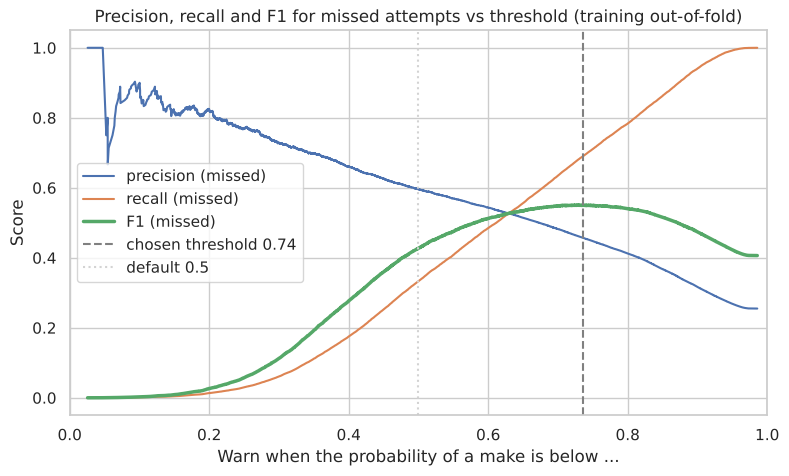

In [3]:
plt.figure(figsize=(9, 5))
plt.plot(1 - thresholds, precision, label='precision (missed)')
plt.plot(1 - thresholds, recall, label='recall (missed)')
plt.plot(1 - thresholds, f1, label='F1 (missed)', lw=2.5)
plt.axvline(threshold, color='grey', ls='--', label=f'chosen threshold {threshold:.2f}')
plt.axvline(0.5, color='lightgrey', ls=':', label='default 0.5')
plt.xlabel('Warn when the probability of a make is below ...'); plt.ylabel('Score')
plt.title('Precision, recall and F1 for missed attempts vs threshold (training out-of-fold)')
plt.legend(); plt.xlim(0, 1); plt.show()

## 2. Apply the threshold to the test set

In [4]:
proba_test = pd.read_csv('../results/test_probas.csv')[column].values     # model fit on the full training sample in notebook 05
default = evaluate(best_name, y_test, proba_test, threshold=0.5)
tuned = evaluate(f'{best_name} (tuned threshold)', y_test, proba_test, threshold=round(threshold, 3))
pd.DataFrame([default, tuned]).round(3)

,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
0,Gradient Boosting,0.500,0.798,0.618,0.826,0.939,0.575,0.297,0.391,0.776
1,Gradient Boosting (tuned threshold),0.736,0.738,0.708,0.887,0.761,0.435,0.656,0.523,0.776


In [5]:
save_result(tuned)

,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
0,Baseline (always made),0.500,0.7807,0.5000,0.7807,1.0000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.500,0.7925,0.5869,0.8132,0.9531,0.5693,0.2208,0.3182,0.7635
2,Decision Tree,0.500,0.7933,0.6119,0.8239,0.9350,0.5553,0.2888,0.3800,0.7650
3,Random Forest,0.500,0.7973,0.6119,0.8236,0.9422,0.5779,0.2816,0.3786,0.7747
4,Gradient Boosting,0.500,0.7977,0.6176,0.8261,0.9385,0.5754,0.2966,0.3914,0.7763
5,Gradient Boosting (tuned threshold),0.736,0.7378,0.7084,0.8873,0.7607,0.4351,0.6561,0.5232,0.7763


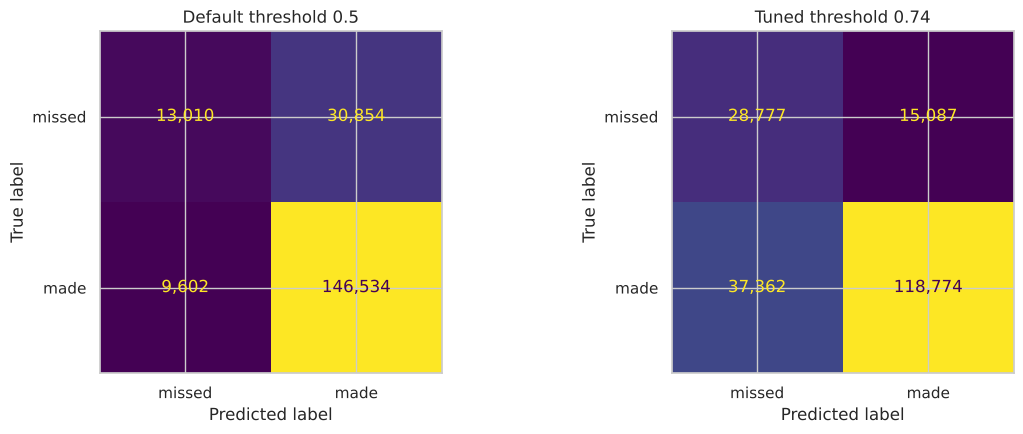

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t, title in [(axes[0], 0.5, 'Default threshold 0.5'), (axes[1], threshold, f'Tuned threshold {threshold:.2f}')]:
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= t).astype(int), display_labels=['missed', 'made'],
                                            ax=ax, colorbar=False, values_format=',')
    ax.set_title(title)
plt.tight_layout(); plt.show()

**Threshold:** the F1-optimal threshold chosen on training data is **warn when P(make) < 0.736**. On the test meets it lifts recall for missed attempts from 0.30 to **0.66**
and balanced accuracy from 0.62 to **0.71**, while precision for missed drops from 0.58 to **0.44**. Accuracy falls (0.80 → 0.74), which is expected: the model now warns more often.

In plain words: the model warns before about **2 out of 3 misses**, and of every 100 warnings about 44 are real misses, twice the 22% miss rate of the test meets.
An evaluator who wants fewer false alarms can lower the threshold, a coach who wants to be warned more often can raise it.

## 3. Value for evaluators: flagging only the riskiest attempts

In [7]:
probas = pd.read_csv('../results/test_probas.csv')
probas['missed'] = 1 - probas['y_true']
total_missed = probas['missed'].sum()
rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.50]:
    n = int(round(share * len(probas)))
    row = {'flag_riskiest_%': int(share * 100), 'attempts_flagged': n}
    for col, label in [(column, 'final'), ('logistic_regression', 'LR')]:
        flagged = probas.sort_values(col, ascending=True).head(n)        # lowest P(make) first
        row[f'{label}_misses_caught_%'] = round(flagged['missed'].sum() / total_missed * 100, 1)
        row[f'{label}_miss_rate_in_flagged_%'] = round(flagged['missed'].mean() * 100, 1)
    row['random_flags_catch_%'] = int(share * 100)
    rows.append(row)
flagging = pd.DataFrame(rows)
print(f'Test set: {len(probas):,} attempts, {total_missed:,} misses ({total_missed / len(probas):.1%})')
flagging

Test set: 200,000 attempts, 43,864 misses (21.9%)


,flag_riskiest_%,attempts_flagged,final_misses_caught_%,final_miss_rate_in_flagged_%,LR_misses_caught_%,LR_miss_rate_in_flagged_%,random_flags_catch_%
0,5,10000,14.9,65.3,13.9,60.9,5
1,10,20000,26.8,58.8,25.3,55.4,10
2,20,40000,46.6,51.1,44.9,49.3,20
3,30,60000,61.9,45.3,60.8,44.4,30
4,50,100000,81.0,35.5,80.2,35.2,50


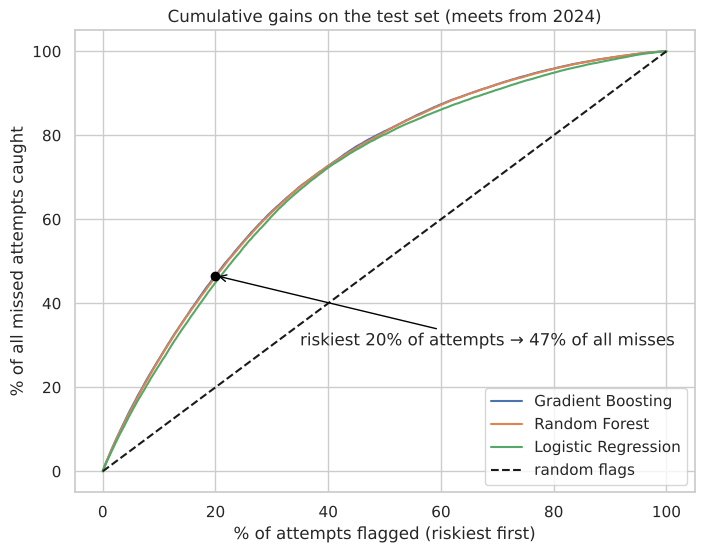

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
x = np.arange(1, len(probas) + 1) / len(probas) * 100
for col, name in [('gradient_boosting', 'Gradient Boosting'), ('random_forest', 'Random Forest'),
                  ('logistic_regression', 'Logistic Regression')]:
    gains = probas.sort_values(col, ascending=True)['missed'].cumsum().values / total_missed * 100
    ax.plot(x, gains, label=name)
ax.plot([0, 100], [0, 100], 'k--', label='random flags')
top20 = flagging.loc[flagging['flag_riskiest_%'] == 20, 'final_misses_caught_%'].item()
ax.scatter([20], [top20], color='black', zorder=5)
ax.annotate(f'riskiest 20% of attempts → {top20:.0f}% of all misses', (20, top20), xytext=(35, 30),
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_xlabel('% of attempts flagged (riskiest first)')
ax.set_ylabel('% of all missed attempts caught')
ax.set_title('Cumulative gains on the test set (meets from 2024)')
ax.legend(loc='lower right'); plt.show()

**Flagging only the riskiest attempts** (test set: 200,000 attempts, 43,864 misses):

| Attempts flagged (riskiest first) | Share of all misses caught | Miss rate among flagged | Random flags |
| --- | --- | --- | --- |
| Riskiest 5% | 14.9% | 65.3% | 5% |
| Riskiest 10% | 26.8% | 58.8% | 10% |
| Riskiest 20% | **46.6%** | 51.1% | 20% |
| Riskiest 30% | 61.9% | 45.3% | 30% |
| Riskiest 50% | 81.0% | 35.5% | 50% |

Watching only the **riskiest 20%** of attempts covers **almost half of all misses**. Among the riskiest 5%, about 2 in 3 attempts are missed, **3× the 21.9% average**.
Gradient Boosting and Random Forest give almost the same curve; Logistic Regression is 1–2 points lower but still far above random.

## 4. Can the probabilities be trusted?

We group test attempts by predicted probability (`pd.cut`) and compare with how often they were actually made. If the model is trustworthy, the two columns match.

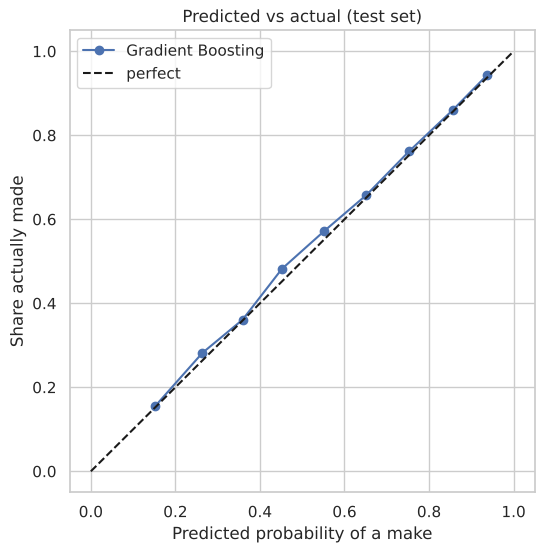

,attempts,mean_predicted,actually_made
bin,,,
"(0.0, 0.2]",414,0.152,0.155
"(0.2, 0.3]",1665,0.264,0.282
"(0.3, 0.4]",6851,0.359,0.361
"(0.4, 0.5]",13683,0.452,0.482
"(0.5, 0.6]",16861,0.552,0.572
"(0.6, 0.7]",18596,0.652,0.658
"(0.7, 0.8]",24938,0.753,0.762
"(0.8, 0.9]",56791,0.857,0.861
"(0.9, 1.0]",60201,0.937,0.943


In [9]:
calib = pd.DataFrame({'predicted': proba_test, 'made': y_test.values})
calib['bin'] = pd.cut(calib['predicted'], [0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
calibration = calib.groupby('bin', observed=True).agg(attempts=('made', 'size'), mean_predicted=('predicted', 'mean'),
                                                      actually_made=('made', 'mean')).round(3)

plt.figure(figsize=(6, 6))
plt.plot(calibration['mean_predicted'], calibration['actually_made'], marker='o', label=best_name)
plt.plot([0, 1], [0, 1], 'k--', label='perfect')
plt.xlabel('Predicted probability of a make'); plt.ylabel('Share actually made')
plt.title('Predicted vs actual (test set)'); plt.legend(); plt.show()
calibration

**Yes.** In every group the predicted and actual make rates are within 3 points: attempts given 75% were made 76.2% of the time, attempts given 45% were made 48.2%.
The model is very slightly **pessimistic** (actual rates a little above the predictions), which fits the time drift: it learned from older meets, and recent meets make more attempts.
So the probability can be read directly as **"about X out of 100 attempts like this one are made"**.

## 5. Use case: choosing the next attempt

The final model is refit on the full training sample and saved (`data/final_model.pkl`, ignored by git) so notebook 08 can reuse it.
`attempt_options()` builds the input row for each weight a lifter is considering and returns the predicted chance of a make.

In [10]:
final = Pipeline([('prep', tree_preprocessor()), ('model', make_model())]).fit(X_train, y_train)
with open('../data/final_model.pkl', 'wb') as f:
    pickle.dump(final, f)

def attempt_options(model, weights, lift, attempt_no, prev_weight=None, prev_result='none', prev_best=None,
                    misses_this_lift=0, misses_earlier_lifts=0, sex='M', equipment='Raw', age=27, bodyweight=83,
                    n_prior_meets=4, days_since_last=180, prior_make_rate=0.75, event='SBD', tested='Yes',
                    meet_country='USA'):
    """Chance of making each candidate weight, for one lifter at one point in the meet."""
    rows = []
    for w in weights:
        jump = w - prev_weight if prev_weight else np.nan
        pct = w / prev_best * 100 if prev_best else np.nan
        rows.append({
            'weight': w, 'weight_to_bw': w / bodyweight, 'pct_prev_best': pct,
            'jump_kg': jump, 'jump_pct': jump / prev_weight * 100 if prev_weight else np.nan,
            'Age': age, 'BodyweightKg': bodyweight, 'n_prior_meets': n_prior_meets,
            'days_since_last': days_since_last, 'prior_make_rate': prior_make_rate, 'attempt_no': attempt_no,
            'misses_this_lift': misses_this_lift, 'misses_earlier_lifts': misses_earlier_lifts,
            'lift': lift, 'prev_result': prev_result, 'Sex': sex, 'Equipment': equipment, 'Event': event,
            'tested': tested, 'meet_country': meet_country,
            'pct_best_bin': 'unused', 'jump_bin': 'unused',      # only the linear model uses the bins
        })
    options = pd.DataFrame(rows)[FEATURES]
    out = options[['weight', 'pct_prev_best', 'jump_kg']].copy()
    out['chance_of_make'] = model.predict_proba(options)[:, 1].round(3)
    return out

**Example 1:** a raw male lifter, 27 years old, 83 kg, competing in the USA. His best squat at earlier meets is **200 kg**,
he has made **195 kg** on his second attempt, and has no misses so far. What are his chances on each possible third attempt?

In [11]:
squat3 = attempt_options(final, weights=[197.5, 200, 202.5, 205, 207.5, 210, 215],
                         lift='Squat', attempt_no=3, prev_weight=195, prev_result='made', prev_best=200)
squat3

,weight,pct_prev_best,jump_kg,chance_of_make
0,197.5,98.75,2.5,0.555
1,200.0,100.00,5.0,0.645
2,202.5,101.25,7.5,0.669
3,205.0,102.50,10.0,0.657
4,207.5,103.75,12.5,0.654
5,210.0,105.00,15.0,0.642
6,215.0,107.50,20.0,0.487


**Example 2:** the same lifter on the **bench press**, best at earlier meets 140 kg. He **missed 135 kg** on his second attempt
(and made 130 kg on his first). Repeat 135, or go up?

In [12]:
bench3 = attempt_options(final, weights=[130, 132.5, 135, 137.5, 140],
                         lift='Bench', attempt_no=3, prev_weight=135, prev_result='missed', prev_best=140,
                         misses_this_lift=1)
bench3

,weight,pct_prev_best,jump_kg,chance_of_make
0,130.0,92.857143,-5.0,0.439
1,132.5,94.642857,-2.5,0.436
2,135.0,96.428571,0.0,0.435
3,137.5,98.214286,2.5,0.483
4,140.0,100.000000,5.0,0.509


**Reading the examples:**

- **Squat:** 200–210 kg (100–105% of his best) all sit around **64–67%**; 215 kg (107.5%) drops to **49%**. The model says that a third attempt up to about 5% over his best is a fair bet, and 10% over is a coin flip.
- The **smallest jump (197.5 kg) gets only 56%**, and on the bench, **repeating 135 kg after a miss (44%) scores lower than 140 kg (51%)**. This is the pattern from notebook 02 §9: lifters choose a tiny jump, or repeat the weight, when the last attempt was **slow or missed for strength**; lifters who go *up* after a miss have probably missed for a **technical reason** (for example a pause or press command) that they expect to fix. The model sees the choice, not the reason.

**So the tool should be used as a risk score, not as an instruction to lift heavier.** It answers "how often are attempts like this made?", which is useful next to the coach's judgment of how the last attempt moved.
Adding that judgment (or measuring bar speed from video) is the natural next step of the project.

In [13]:
flagging.to_csv('../results/risk_flagging.csv', index=False)
calibration.to_csv('../results/calibration.csv')
pd.concat([squat3.assign(example='squat 3rd after made 195'), bench3.assign(example='bench 3rd after missed 135')]).to_csv(
    '../results/attempt_examples.csv', index=False)
json.dump({'final_model': best_name, 'warn_if_p_make_below': round(threshold, 3)},
          open('../results/threshold.json', 'w'), indent=2)